In [1]:
import pandas as pd

tres = pd.read_csv("AB_Test_Results.csv")
tres.columns = ["user_id", "var_name", "rev"]

tres.head()

,user_id,var_name,rev
0,737,variant,0.0
1,2423,control,0.0
2,9411,control,0.0
3,7311,control,0.0
4,6174,variant,0.0


In [2]:
tres.shape

(10000, 3)

In [3]:
tres.isna().sum()

user_id     0
var_name    0
rev         0
dtype: int64

In [4]:
len(tres["user_id"].unique())

6324

In [5]:
tres.dtypes

user_id       int64
var_name     object
rev         float64
dtype: object

In [6]:
tres.groupby(by = ["user_id", "var_name"]).sum()

rev
user_id var_name      
2       control   0.00
3       control   0.00
        variant   0.00
4       variant   0.00
5       variant   0.00
...                ...
9996    control   0.00
        variant   6.46
9998    control   0.00
10000   control   0.00
        variant   0.00

[7865 rows x 1 columns]

In [8]:
arr = tres.to_numpy()
double_users = []

for i in arr:

    for j in arr:

        if i[0] == j[0]:

            if i[1] != j[1]:
                double_users.append(i[0])
                break

double_users

[2423,
 9411,
 7311,
 2849,
 6205,
 2529,
 8406,
 9085,
 4572,
 6588,
 598,
 2667,
 7951,
 3610,
 5599,
 8281,
 2653,
 8275,
 4303,
 8796,
 4064,
 3354,
 5142,
 1145,
 9234,
 8976,
 7704,
 9711,
 7931,
 1271,
 5834,
 4647,
 3001,
 1380,
 4865,
 7514,
 6750,
 2460,
 7704,
 2954,
 5242,
 1967,
 5015,
 9224,
 8599,
 6654,
 7605,
 3112,
 1814,
 5290,
 7696,
 8974,
 8542,
 2673,
 4558,
 8002,
 7466,
 3352,
 9429,
 9933,
 2592,
 3773,
 9010,
 1229,
 6729,
 8271,
 4005,
 6678,
 5051,
 9465,
 2102,
 6855,
 8406,
 8092,
 3581,
 7088,
 4740,
 8469,
 1611,
 9091,
 6167,
 1101,
 1718,
 4879,
 245,
 4801,
 6236,
 6549,
 6539,
 9847,
 9915,
 6393,
 7773,
 2187,
 8278,
 1282,
 8474,
 4053,
 2923,
 4153,
 1546,
 7495,
 6473,
 4064,
 8109,
 351,
 652,
 9661,
 8993,
 2359,
 6231,
 5340,
 5205,
 6539,
 2849,
 384,
 998,
 2579,
 3017,
 2512,
 4351,
 1959,
 7405,
 999,
 4383,
 9942,
 5537,
 7720,
 2310,
 5094,
 1358,
 701,
 8300,
 4617,
 5503,
 6865,
 3284,
 3741,
 5377,
 9824,
 9893,
 2687,
 4530,
 1139,


In [9]:
mask = tres["user_id"].isin(double_users)

In [10]:
cl_tres = tres.loc[~mask]

In [11]:
cl_tres.shape

(6070, 3)

In [14]:
cl_tres.sort_values(by = ["user_id"], ascending = True)

,user_id,var_name,rev
3479,2,control,0.0
7076,2,control,0.0
2406,2,control,0.0
9077,4,variant,0.0
9155,5,variant,0.0
...,...,...,...
3260,9992,control,0.0
9290,9993,control,0.0
2749,9995,variant,0.0
5673,9995,variant,0.0


In [67]:
dd_cl_tres = cl_tres.drop_duplicates(subset = ["user_id"])

In [68]:
dd_cl_tres = dd_cl_tres[dd_cl_tres["rev"] > 0]

In [69]:
dd_cl_tres.shape

(74, 3)

In [70]:
dd_cl_tres.dtypes

user_id       int64
var_name     object
rev         float64
dtype: object

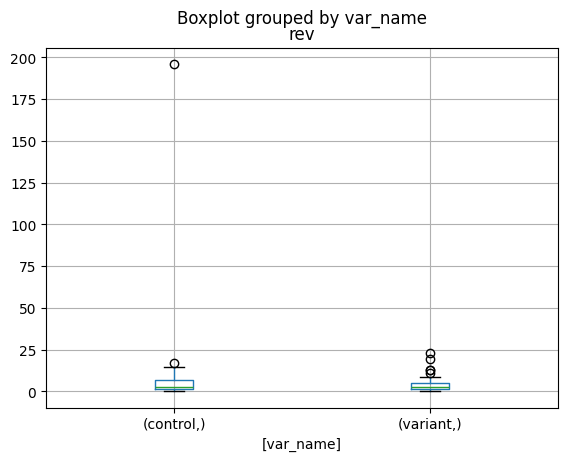

In [71]:
import matplotlib.pyplot as plt

dd_cl_tres.boxplot(by = ["var_name"], column = ["rev"])
plt.show()

In [72]:
rev_q1 = dd_cl_tres["rev"].quantile(0.25)
rev_q3 = dd_cl_tres["rev"].quantile(0.75)
rev_iqr = rev_q3 - rev_q1

dd_cl_tres = dd_cl_tres[(dd_cl_tres["rev"] <= rev_q3 + 1.5 * rev_iqr) & (dd_cl_tres["rev"] > rev_q1 - 1.5 * rev_iqr)]

In [78]:
rev_q3 - 1.5 * rev_iqr

-0.9837500000000006

In [73]:
plt.clf()

<Figure size 640x480 with 0 Axes>

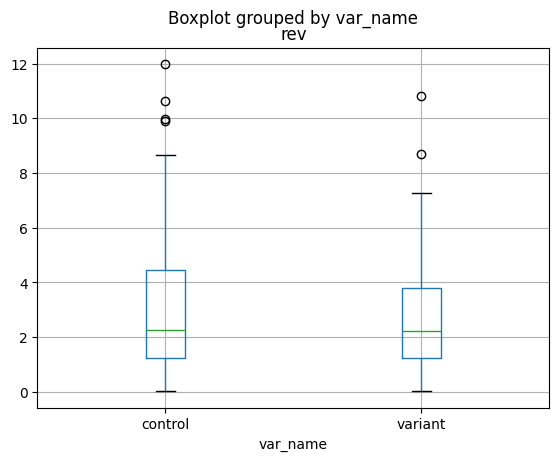

In [74]:
dd_cl_tres.boxplot(column = ["rev"], by = "var_name")
plt.show()

In [75]:
dd_cl_tres.shape

(66, 3)

In [76]:
dd_cl_tres.sort_values(by = "rev", ascending = True)

,user_id,var_name,rev
8838,7157,variant,0.02
7140,3536,control,0.02
2974,5063,control,0.02
2314,3578,variant,0.04
4991,6271,control,0.50
...,...,...,...
333,8020,control,9.91
6483,2212,control,9.99
628,6365,control,10.63
2726,3326,variant,10.82


In [79]:
dd_cl_tres.groupby(by = "var_name").count()

,user_id,rev
var_name,,
control,36,36
variant,30,30
